In [2]:
import utils.database as db
from utils import cellmath, cellplot
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

frame = 70
data = db.get_frame(frame, db.get_database_path())

cell_data = data["cells"]
dbonds_data = data["directed_bonds"]
vertices_data = data["vertices"]

Average Area difference (Magnitude) =  12.044


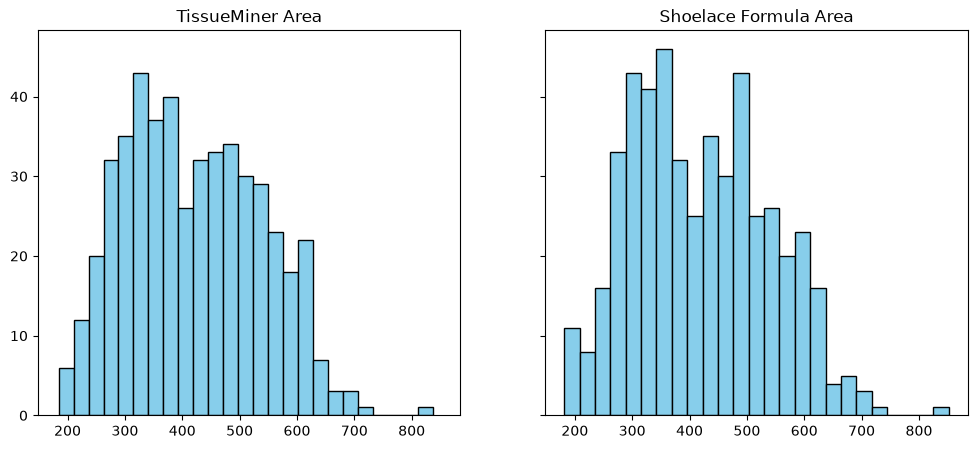

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, sharex=True , sharey=True, figsize=(12, 5))

cleaned_cell_data = cell_data[cell_data["cell_id"] != 10000]

ax1.hist(cleaned_cell_data["area"], bins=25, color="skyblue", edgecolor="black")
ax1.set_title("TissueMiner Area")

shoelace_areas = []
for id in cleaned_cell_data["cell_id"]:
    vList = cellmath.get_cell_verticies(id, dbonds_data, vertices_data)
    shoelace_areas.append(cellmath.shoelace_area(vList))


ax2.hist(shoelace_areas, bins=25, color="skyblue", edgecolor="black")
ax2.set_title("Shoelace Formula Area")
    
diff = cleaned_cell_data["area"] - pd.Series(shoelace_areas)

cell_data_area_list  = cleaned_cell_data["area"].tolist()

diff = []
for i, val in enumerate(cell_data_area_list):
    diff.append(shoelace_areas[i] - val)

print("Average Area difference (Magnitude) = ", np.round(np.mean(np.abs(diff)), 3))

Text(0, 0.5, 'Cell Count')

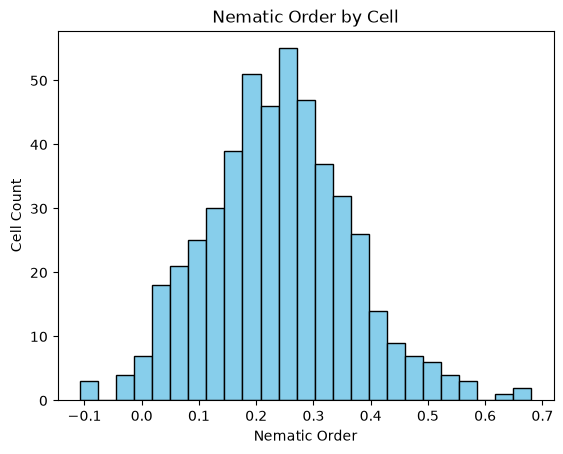

In [4]:
nematic_orders = []
for id in cleaned_cell_data["cell_id"]:
    vList = cellmath.get_cell_verticies(id, dbonds_data, vertices_data)
    real, imaginary = cellmath.calc_order(vList, 2)
    nematic_orders.append(real)

plt.hist(nematic_orders, bins=25, color="skyblue", edgecolor="black")
plt.title("Nematic Order by Cell")
plt.xlabel("Nematic Order")
plt.ylabel("Cell Count")

10369.556468172485


np.int64(10708)

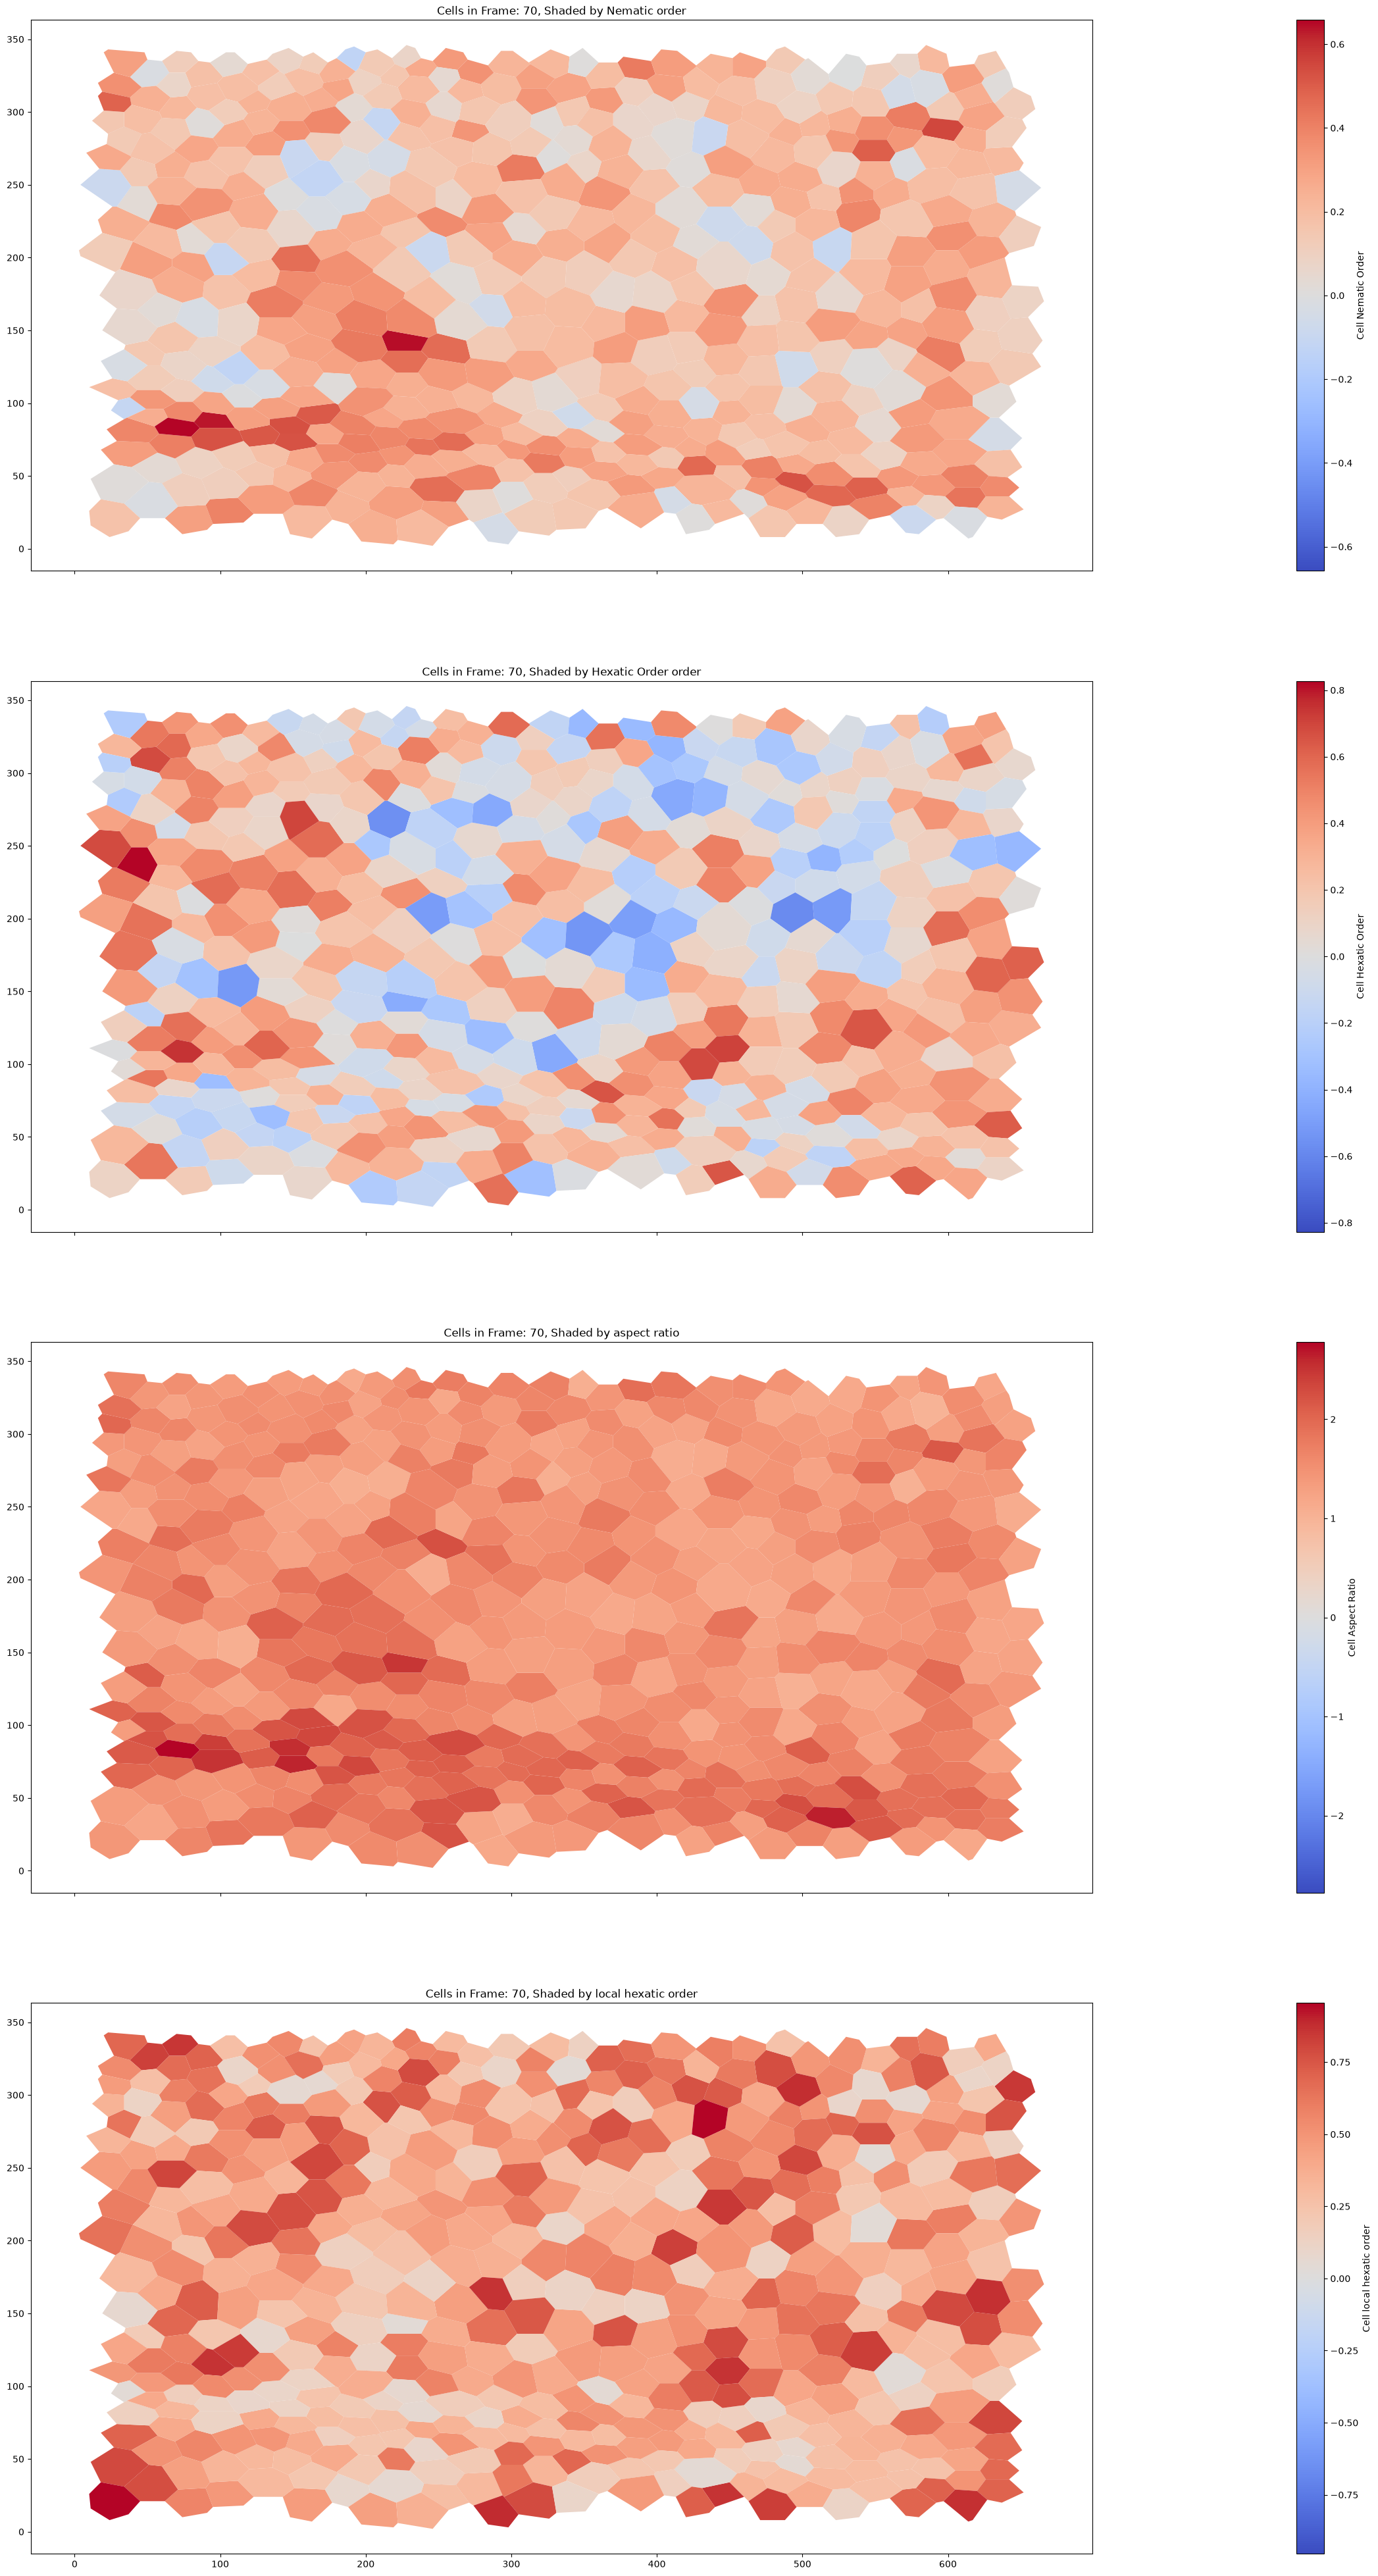

In [5]:

fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(100, 50), sharex=True, sharey=True)

n_order_dict = cellmath.nematic_order_dict(cleaned_cell_data, dbonds_data, vertices_data, False)
hexatic_order_dict = cellmath.order_dict(cleaned_cell_data, dbonds_data, vertices_data, 6, False) 
aspect_ratio_dict = cellmath.aspect_ratio_dict(cleaned_cell_data, dbonds_data, vertices_data)
local_hexatic_order_dict = cellmath.local_hexatic_order_dict(cleaned_cell_data, dbonds_data, vertices_data)

cellplot.draw_cell_boundaries(
    ax1,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    n_order_dict,
    border_width=0.001
)

ax1.set_title(f"Cells in Frame: {frame}, Shaded by Nematic order")
cellplot.plotColorBar(ax1, fig, n_order_dict, True, "Cell Nematic Order")

cellplot.draw_cell_boundaries(
    ax2,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    hexatic_order_dict,
    border_width=0.001
)

ax2.set_title(f"Cells in Frame: {frame}, Shaded by Hexatic Order order")
cellplot.plotColorBar(ax2, fig, hexatic_order_dict, True, "Cell Hexatic Order")

cellplot.draw_cell_boundaries(
    ax3,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    aspect_ratio_dict,
    border_width=0.001
)

ax3.set_title(f"Cells in Frame: {frame}, Shaded by aspect ratio")
cellplot.plotColorBar(ax3, fig, aspect_ratio_dict, True, "Cell Aspect Ratio")

cellplot.draw_cell_boundaries(
    ax4,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    local_hexatic_order_dict,
    border_width=0.001
)

ax4.set_title(f"Cells in Frame: {frame}, Shaded by local hexatic order")
cellplot.plotColorBar(ax4, fig, local_hexatic_order_dict, True, "Cell local hexatic order")

print(np.mean(list(local_hexatic_order_dict)))
max(local_hexatic_order_dict)

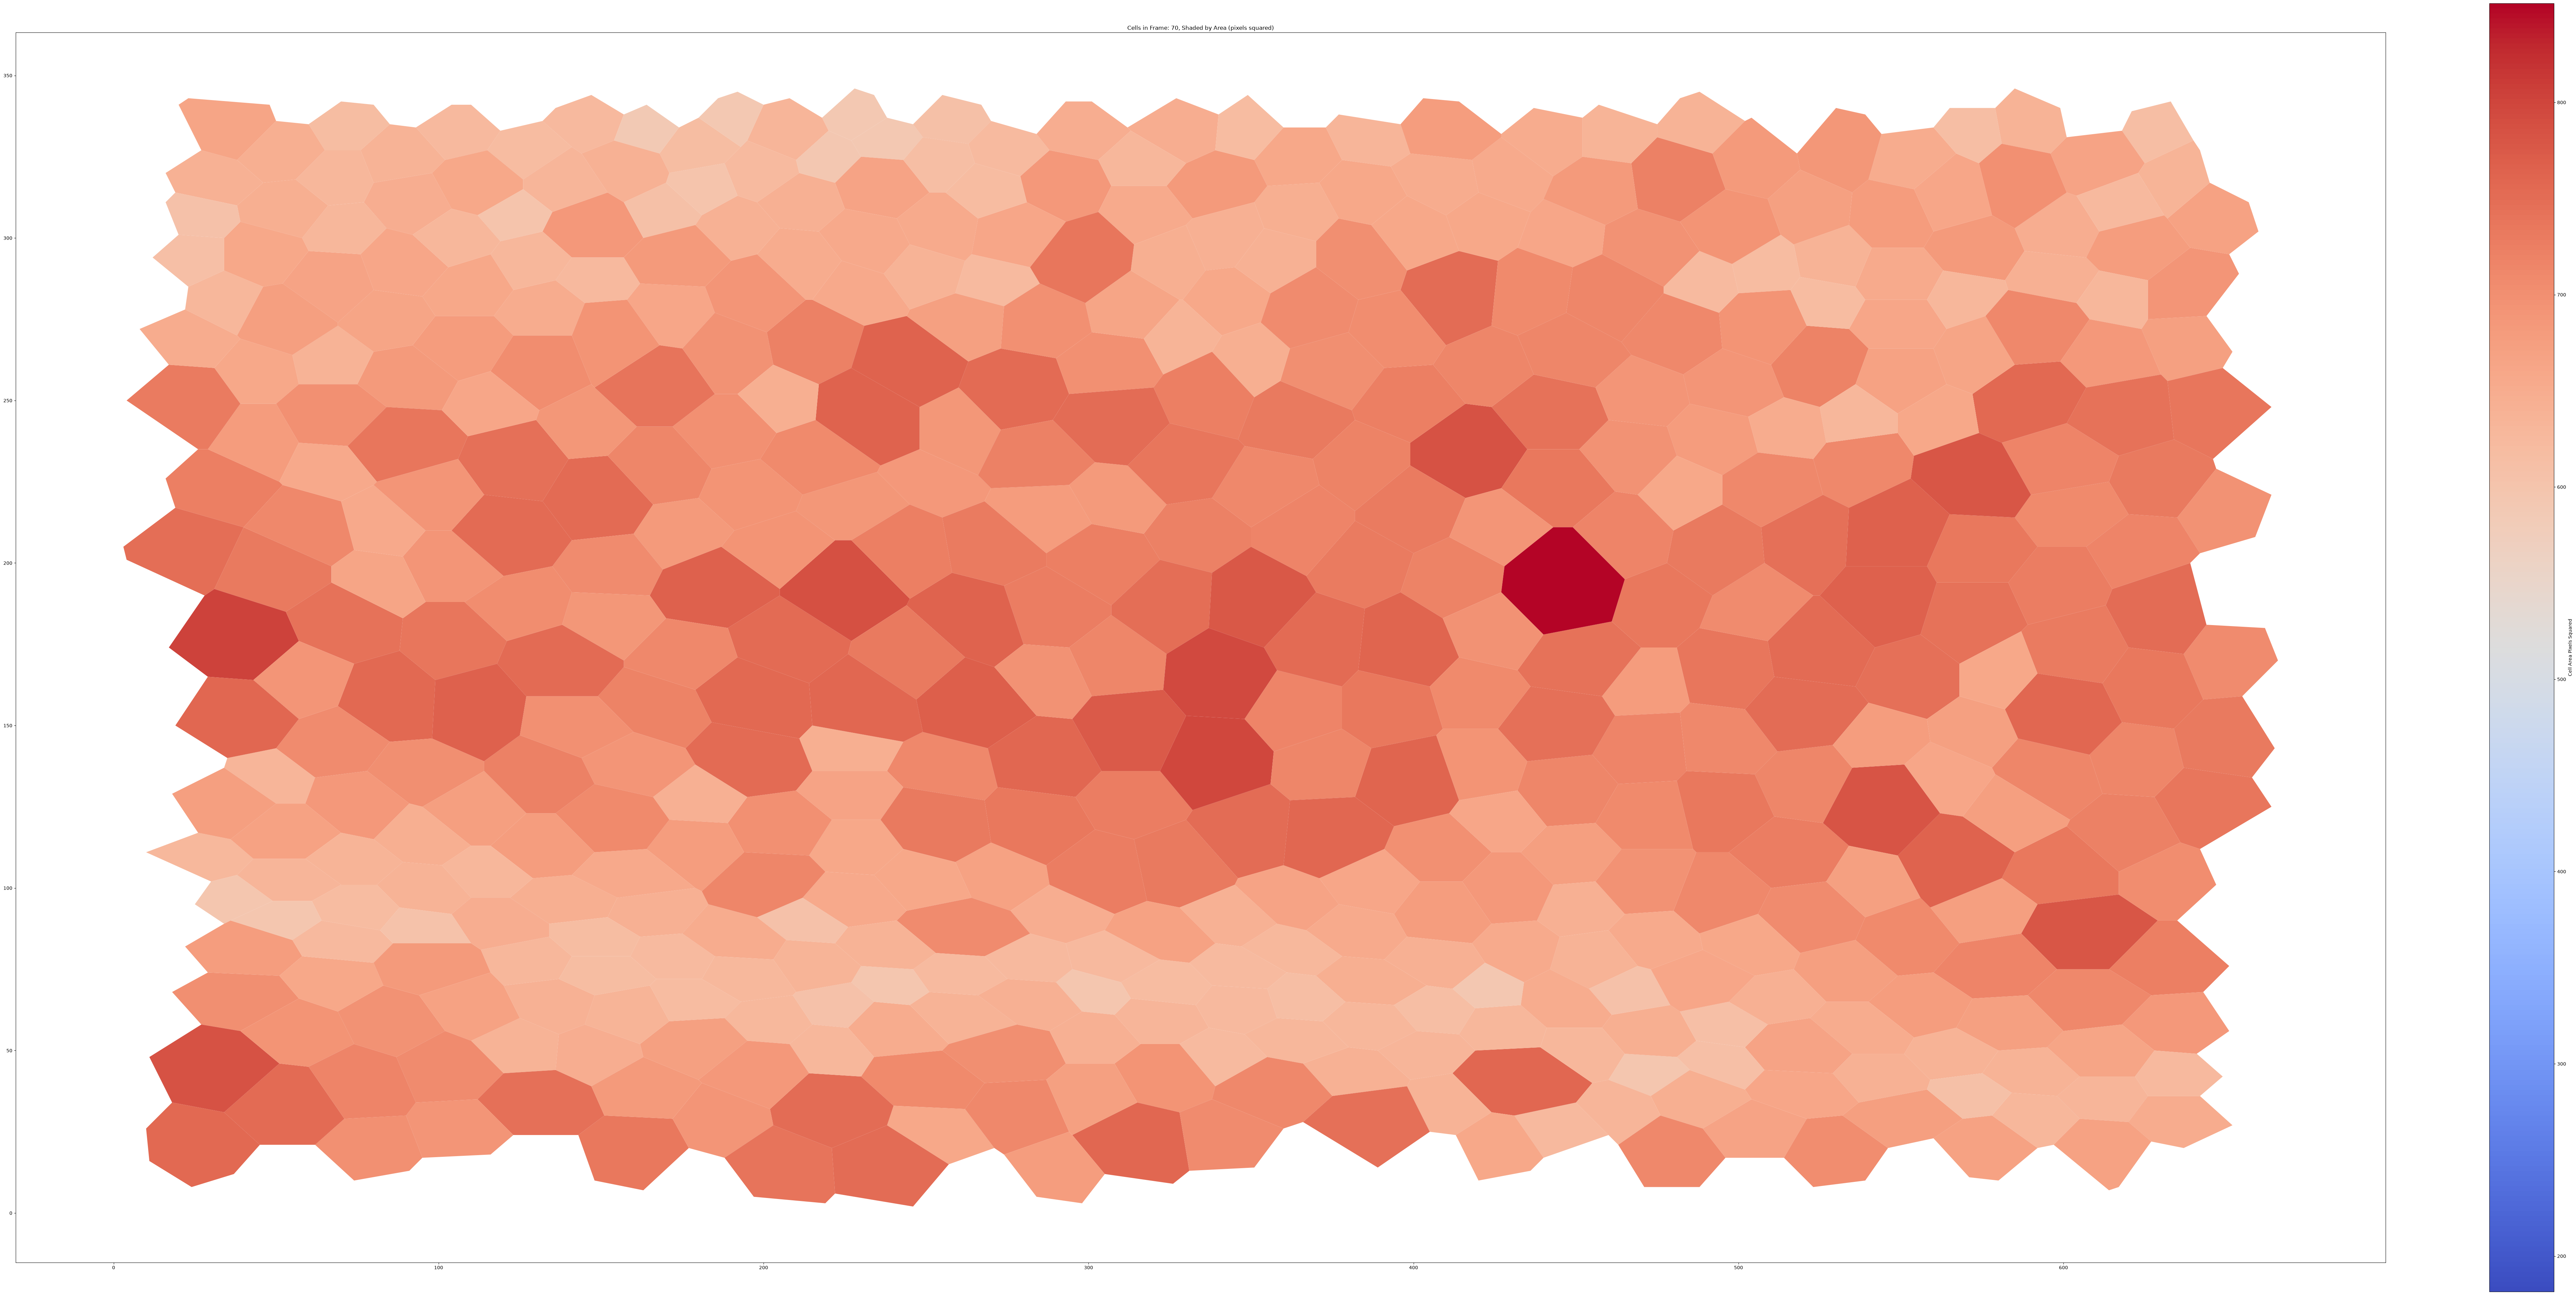

In [6]:
fig, ax = plt.subplots(figsize=(100,50))

shoelace_area_dict = dict(zip(cleaned_cell_data["cell_id"], shoelace_areas))

cellplot.draw_cell_boundaries(
    ax,
    frame,
    cleaned_cell_data["cell_id"].tolist(),
    shoelace_area_dict,
    border_width=0.001
)

ax.set_title(f"Cells in Frame: {frame}, Shaded by Area (pixels squared)")
cellplot.plotColorBar(ax, fig, shoelace_area_dict, False, "Cell Area Pixels Squared")

In [ ]:
print(np.mean(list(n_order_dict.values())))
print(np.mean(list(hexatic_order_dict.values())))
np.mean(list(aspect_ratio_dict.values()))

0.20141204
0.13656904


np.float64(1.5844862028368456)